# Human Decision Making Under Uncertainty

*Imports*

In [131]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.model_selection import cross_validate
from scipy.stats import sem
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
import optuna
import lightgbm as lgb


*Data Loading and Inspection*
- Read the .json file using *orient='index'*, meaning that each key of the dictionary is treated as row index and convert it into a DataFrame
- Read the .csv file and convert it into a DataFrame
- Display both datasets to inspect their structure and available variables

In [132]:
# read json
df_problems = pd.read_json("c13k_problems.json", orient='index')

# read csv
df_choices = pd.read_csv("c13k_selections.csv")

with pd.option_context('display.max_columns', None):
    display(df_choices, df_problems)

,Problem,Feedback,n,Block,Ha,pHa,La,Hb,pHb,Lb,LotShapeB,LotNumB,Amb,Corr,bRate,bRate_std
0,1,True,15,2,26,0.95,-1,23,0.05,21,0,1,False,0,0.626667,0.384460
1,2,True,15,4,14,0.60,-18,8,0.25,-5,0,1,True,-1,0.493333,0.413118
2,3,True,17,4,2,0.50,0,1,1.00,1,0,1,False,0,0.611765,0.432843
3,4,True,18,3,37,0.05,8,87,0.25,-31,1,2,False,0,0.222222,0.387383
4,5,False,15,1,26,1.00,26,45,0.75,-36,2,5,False,0,0.586667,0.450185
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14563,13002,True,15,3,30,1.00,30,42,0.80,0,0,1,True,0,0.367619,0.302731
14564,13003,True,15,5,70,0.50,-42,18,0.80,7,0,1,False,0,0.760000,0.364104
14565,13004,True,15,5,8,0.40,-17,31,0.40,-34,1,6,False,0,0.666667,0.367747
14566,13005,True,15,2,89,0.50,-49,45,0.50,-12,0,1,False,0,0.386667,0.381476


,B,A
0,"[[0.9500000000000001, 21.0], [0.05, 23.0]]","[[0.9500000000000001, 26.0], [0.05, -1.0]]"
1,"[[0.75, -5.0], [0.25, 8.0]]","[[0.6000000000000001, 14.0], [0.4, -18.0]]"
2,"[[1.0, 1.0]]","[[0.5, 2.0], [0.5, 0.0]]"
3,"[[0.75, -31.0], [0.125, 86.5], [0.125, 87.5]]","[[0.05, 37.0], [0.9500000000000001, 8.0]]"
4,"[[0.25, -36.0], [0.375, 41.0], [0.1875, 43.0],...","[[1.0, 26.0], [0.0, 26.0]]"
...,...,...
14563,"[[0.199999999999999, 0.0], [0.8, 42.0]]","[[1.0, 30.0], [0.0, 30.0]]"
14564,"[[0.199999999999999, 7.0], [0.8, 18.0]]","[[0.5, 70.0], [0.5, -42.0]]"
14565,"[[0.6000000000000001, -34.0], [0.0125, 28.5], ...","[[0.4, 8.0], [0.6000000000000001, -17.0]]"
14566,"[[0.5, -12.0], [0.5, 45.0]]","[[0.5, 89.0], [0.5, -49.0]]"


*Data Merging*
- *join* the two DataFrames into a single dataset using a *left join* ensuring that all choice observations are retained

In [133]:
# join
final_data = df_choices.join(df_problems, how="left")
final_data

,Problem,Feedback,n,Block,Ha,pHa,La,Hb,pHb,Lb,LotShapeB,LotNumB,Amb,Corr,bRate,bRate_std,B,A
0,1,True,15,2,26,0.95,-1,23,0.05,21,0,1,False,0,0.626667,0.384460,"[[0.9500000000000001, 21.0], [0.05, 23.0]]","[[0.9500000000000001, 26.0], [0.05, -1.0]]"
1,2,True,15,4,14,0.60,-18,8,0.25,-5,0,1,True,-1,0.493333,0.413118,"[[0.75, -5.0], [0.25, 8.0]]","[[0.6000000000000001, 14.0], [0.4, -18.0]]"
2,3,True,17,4,2,0.50,0,1,1.00,1,0,1,False,0,0.611765,0.432843,"[[1.0, 1.0]]","[[0.5, 2.0], [0.5, 0.0]]"
3,4,True,18,3,37,0.05,8,87,0.25,-31,1,2,False,0,0.222222,0.387383,"[[0.75, -31.0], [0.125, 86.5], [0.125, 87.5]]","[[0.05, 37.0], [0.9500000000000001, 8.0]]"
4,5,False,15,1,26,1.00,26,45,0.75,-36,2,5,False,0,0.586667,0.450185,"[[0.25, -36.0], [0.375, 41.0], [0.1875, 43.0],...","[[1.0, 26.0], [0.0, 26.0]]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14563,13002,True,15,3,30,1.00,30,42,0.80,0,0,1,True,0,0.367619,0.302731,"[[0.199999999999999, 0.0], [0.8, 42.0]]","[[1.0, 30.0], [0.0, 30.0]]"
14564,13003,True,15,5,70,0.50,-42,18,0.80,7,0,1,False,0,0.760000,0.364104,"[[0.199999999999999, 7.0], [0.8, 18.0]]","[[0.5, 70.0], [0.5, -42.0]]"
14565,13004,True,15,5,8,0.40,-17,31,0.40,-34,1,6,False,0,0.666667,0.367747,"[[0.6000000000000001, -34.0], [0.0125, 28.5], ...","[[0.4, 8.0], [0.6000000000000001, -17.0]]"
14566,13005,True,15,2,89,0.50,-49,45,0.50,-12,0,1,False,0,0.386667,0.381476,"[[0.5, -12.0], [0.5, 45.0]]","[[0.5, 89.0], [0.5, -49.0]]"


*Data Validation*
- Check the *shape* of the dataset to confirm that no rows were lost during the merge
- Use *.info()* to inspect data types and verify the presence of non-null values
- Use *.isna()* to identify and quantify any missing values

In [134]:
final_data.shape
final_data.info()
final_data.isna().sum().head(20)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14568 entries, 0 to 14567
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Problem    14568 non-null  int64  
 1   Feedback   14568 non-null  bool   
 2   n          14568 non-null  int64  
 3   Block      14568 non-null  int64  
 4   Ha         14568 non-null  int64  
 5   pHa        14568 non-null  float64
 6   La         14568 non-null  int64  
 7   Hb         14568 non-null  int64  
 8   pHb        14568 non-null  float64
 9   Lb         14568 non-null  int64  
 10  LotShapeB  14568 non-null  int64  
 11  LotNumB    14568 non-null  int64  
 12  Amb        14568 non-null  bool   
 13  Corr       14568 non-null  int64  
 14  bRate      14568 non-null  float64
 15  bRate_std  14568 non-null  float64
 16  B          14568 non-null  object 
 17  A          14568 non-null  object 
dtypes: bool(2), float64(4), int64(10), object(2)
memory usage: 1.8+ MB


Problem      0
Feedback     0
n            0
Block        0
Ha           0
pHa          0
La           0
Hb           0
pHb          0
Lb           0
LotShapeB    0
LotNumB      0
Amb          0
Corr         0
bRate        0
bRate_std    0
B            0
A            0
dtype: int64

*Boolean Variable Encoding*
- Some features in the dataset are stored as boolean values (True/False), since most machine learning models require numerical inputs, these variables must be converted into a numeric format
- All boolean columns are therefore encoded as binary variables:
    - True → 1 
    - False → 0

In [135]:
# Convert all boolean columns to 0/1
bool_cols = final_data.select_dtypes(include="bool").columns
final_data[bool_cols] = final_data[bool_cols].astype(int)
# final_data


##### Additional Features

*Expected Value Calculation*
- The expected value (EV) of a gamble is computed as a probability-weighted average of possible outcomes
- Mathematically: *$$EV = p \cdot H + (1 - p) \cdot L$$*
    - More generally: *$$EV = \sum_i p_i \cdot x_i$$​*
- Define a function for the *expected value* and apply to A and B

Explanation: each cell (row) contains a list of two elements [p, x], where p represents the probability of an outcome and x the corresponding payoff. The expected value is the sum of p*x across all possible outcomes
Example: gamble = [[0.95, 21.0], [0.05, 23.0]] so the expected value is 0.95⋅21.0 + 0.05⋅23.0

In [136]:
def expected_value(gamble): 
    "gamble: list of [probability, payoff] pairs"

    ev = sum(p * x for p, x in gamble)

    return ev

# apply the expected_value funtion 
final_data["EV_B"] = final_data["B"].apply(expected_value)
final_data["EV_A"] = final_data["A"].apply(expected_value)
# final_data

*Expected Value Difference*
- Compute the difference between the expected values of options B and A
- This difference captures how much better or worse option B is compared to A on average (since bRate represents the average choice rate over many participants, the expected value difference provides a natural explanatory variable)
- Mathematically: *$$EV_{\text{diff}} = EV_B - EV_A$$*

    - EV_diff > 0: option B has a higher average payoff → bRate is expected to increase
    - EV_diff < 0: option B has a lower average payoff → bRate is expected to decrease
    - EV_diff = 0: both options have the same expected value → participants are expected to be indifferent

In [137]:
final_data["EV_difference"] = final_data["EV_B"] - final_data["EV_A"]
final_data[["EV_A", "EV_B", "EV_difference", "bRate"]].head()

# final_data

,EV_A,EV_B,EV_difference,bRate
0,24.65,21.10,-3.55,0.626667
1,1.20,-1.75,-2.95,0.493333
2,1.00,1.00,0.00,0.611765
3,9.45,-1.50,-10.95,0.222222
4,26.00,24.75,-1.25,0.586667


*Risk Calculation*
- Risk captures the degree of uncertainty in the outcomes of a gamble
    - Low Risk: outcomes are predictable (safe)
    - High Risk: outcomes are very uncertain (risky)
- Mathematically : *$$\text{Risk} = \sum_i p_i \left(x_i - EV\right)^2$$*
- Interpretation:
    - Small variance → outcomes are concentrated around the expected value (safer option) so there are predictable / safe
    - Large variance → outcomes are more spread out so there are uncertain / risky
- Define a function for the *risk* and apply to A and B

In [138]:
def risk_variance(gamble):
    """
    gamble: list of [probability, payoff] pairs
    returns the variance of the gamle
    """
    ev = expected_value(gamble)
    risk = sum(p * (x - ev)**2 for p, x in gamble)

    return risk

# apply the risk_variance funtion
final_data["Risk_B"] = final_data["B"].apply(risk_variance)
final_data["Risk_A"] = final_data["A"].apply(risk_variance)
final_data[["EV_A", "Risk_A", "EV_B", "Risk_B"]].head()
# final_data

,EV_A,Risk_A,EV_B,Risk_B
0,24.65,34.6275,21.10,0.1900
1,1.20,245.7600,-1.75,31.6875
2,1.00,1.0000,1.00,0.0000
3,9.45,39.9475,-1.50,2610.8125
4,26.00,0.0000,24.75,1273.6875


*Risk Difference*
- Compute the difference in risk between options B and A
- his difference captures how much more or less uncertain option B is compared to A
- Risk focuses on the spread of possible outcomes, not their average payoff
    - Mathematically: *$$\text{Risk}_{\text{diff}} = \text{Risk}_B - \text{Risk}_A$$*
- Interpretation:
    - Risk_diff > 0: option B is riskier than A → higher outcome uncertainty
    - Risk_diff < 0: option B is less risky than A → more predictable outcomes
    - Risk_diff = 0: both options have the same level of risk

In [139]:
final_data["Risk_difference"] = final_data["Risk_B"] - final_data["Risk_A"]
final_data[["Risk_A", "Risk_B", "Risk_difference", "bRate"]].head()
# final_data

,Risk_A,Risk_B,Risk_difference,bRate
0,34.6275,0.1900,-34.4375,0.626667
1,245.7600,31.6875,-214.0725,0.493333
2,1.0000,0.0000,-1.0000,0.611765
3,39.9475,2610.8125,2570.8650,0.222222
4,0.0000,1273.6875,1273.6875,0.586667


*Best and Worst Outcomes*
- Define a function for the *best* and *worst* outcome and apply to A and B
    - The best outcome of a gamble corresponds to the highest possible payoff (win)
    - The worst outcome corresponds to the lowest possible payoff (loss)

In [140]:
# helper function
def best_outcome(gamble):
    return max(x for p, x in gamble)

def worst_outcome(gamble):
    return min(x for p, x in gamble)

# apply to A and B
final_data["Best_B"] = final_data["B"].apply(best_outcome)
final_data["Worst_B"] = final_data["B"].apply(worst_outcome)

final_data["Best_A"] = final_data["A"].apply(best_outcome)
final_data["Worst_A"] = final_data["A"].apply(worst_outcome)

final_data[["Best_B", "Worst_B", "Best_A", "Worst_A"]].head()


,Best_B,Worst_B,Best_A,Worst_A
0,23.0,21.0,26.0,-1.0
1,8.0,-5.0,14.0,-18.0
2,1.0,1.0,2.0,0.0
3,87.5,-31.0,37.0,8.0
4,71.0,-36.0,26.0,26.0


*Best and Worst Outcome Differences*
- Compute the differences in the best and worst possible outcomes between options B and A
- These differences capture how the upside potential and downside risk of option B compare to option A
    - Mathematically: *$$\text{Best}_{\text{diff}} = \text{Best}_B - \text{Best}_A$$*
    & 
                    *$$\text{Worst}_{\text{diff}} = \text{Worst}_B - \text{Worst}_A$$*
- Interpretation:
    - Best_difference > 0: option B offers a higher potential upside than A
    - Best_difference < 0: option B has a lower maximum payoff than A
    - Worst_difference < 0: option B has a worse downside (larger potential loss) than A
    - Worst_difference > 0: option B has a less severe downside than A

In [141]:
# best & worst difference
final_data["Best_difference"] = final_data["Best_B"] - final_data["Best_A"]
final_data["Worst_difference"] = final_data["Worst_B"] - final_data["Worst_A"]

final_data[["Best_difference", "Worst_difference"]].head()

,Best_difference,Worst_difference
0,-3.0,22.0
1,-6.0,13.0
2,-1.0,1.0
3,50.5,-39.0
4,45.0,-62.0


*Drop Columns A and B*
- Drop the original columns A and B from the datase
- All relevant information contained in these columns has already been extracted

In [142]:
final_data = final_data.drop(columns=["A", "B"])
final_data

,Problem,Feedback,n,Block,Ha,pHa,La,Hb,pHb,Lb,...,EV_difference,Risk_B,Risk_A,Risk_difference,Best_B,Worst_B,Best_A,Worst_A,Best_difference,Worst_difference
0,1,1,15,2,26,0.95,-1,23,0.05,21,...,-3.55,0.1900,3.462750e+01,-34.4375,23.0,21.0,26.0,-1.0,-3.0,22.0
1,2,1,15,4,14,0.60,-18,8,0.25,-5,...,-2.95,31.6875,2.457600e+02,-214.0725,8.0,-5.0,14.0,-18.0,-6.0,13.0
2,3,1,17,4,2,0.50,0,1,1.00,1,...,0.00,0.0000,1.000000e+00,-1.0000,1.0,1.0,2.0,0.0,-1.0,1.0
3,4,1,18,3,37,0.05,8,87,0.25,-31,...,-10.95,2610.8125,3.994750e+01,2570.8650,87.5,-31.0,37.0,8.0,50.5,-39.0
4,5,0,15,1,26,1.00,26,45,0.75,-36,...,-1.25,1273.6875,0.000000e+00,1273.6875,71.0,-36.0,26.0,26.0,45.0,-62.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14563,13002,1,15,3,30,1.00,30,42,0.80,0,...,3.60,282.2400,0.000000e+00,282.2400,42.0,0.0,30.0,30.0,12.0,-30.0
14564,13003,1,15,5,70,0.50,-42,18,0.80,7,...,1.80,19.3600,3.136000e+03,-3116.6400,18.0,7.0,70.0,-42.0,-52.0,49.0
14565,13004,1,15,5,8,0.40,-17,31,0.40,-34,...,-1.00,1014.5000,1.500000e+02,864.5000,33.5,-34.0,8.0,-17.0,25.5,-17.0
14566,13005,1,15,2,89,0.50,-49,45,0.50,-12,...,-3.50,812.2500,4.761000e+03,-3948.7500,45.0,-12.0,89.0,-49.0,-44.0,37.0


*One-Hot Encoding of Categorical Variable*
- The variable *LotShapeB* is categorical, taking values {0,1,2,3} 
- Since these values represent categories rather than numerical magnitudes, one-hot encoding is used to convert them into binary (dummy) variables
- A separate binary column is created for each category
- The original categorical column is then removed and replaced with the encoded features

In [143]:
enc = OneHotEncoder(
    sparse_output=False, # so we get a NumPy array
    handle_unknown="ignore"
)

# fit encoder on LotShapeB
LotShapeB_encoded = enc.fit_transform(final_data[["LotShapeB"]])

lotshape_cols = enc.get_feature_names_out(["LotShapeB"])
lotshape_df = pd.DataFrame(
    LotShapeB_encoded,
    columns=lotshape_cols,
    index=final_data.index
)

# replace the original column
final_data = final_data.drop(columns=["LotShapeB"])
final_data = pd.concat([final_data, lotshape_df], axis=1)
# final_data


*ML Methods*
- Set a fixed random seed to ensure reproducibility of the results
- Define *bRate* as the target variable, representing the average choice rate of option B
- Construct the feature matrix X by removing the target variable and other non-predictive or auxiliary columns
    - target: *bRate*
    - non-predictive identifier: *Problem*
    - auxiliary/post-outcome variable: *bRate_std* (it leaks information about the target)
- The dataset is then split into training and test sets using an 80/20 split   
    - The test set is kept as a true holdout and is never used during hyperparameter tuning (e.g. Optuna), ensuring an unbiased evaluation of the final model

In [144]:
SEED = 42
np.random.seed(SEED)

# data Preperation
y = final_data["bRate"]
X = final_data.drop(columns=["bRate", "Problem", "bRate_std"])

# split 
X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

1. ##### Ridge regressor: 
- Feature type identification
    -  Separate predictors based on their data type
        - Numeric features
        - Boolean features
        - Numeric features are standardized, while boolean features are kept unchanged
        - Boolean features are explicitly handled in the preprocessing pipeline, even if they have been previously converted to numeric form, in order to ensure pipeline robustness and guard against unintended data-type inconsistencies
- Column-wise preprocessing: 
    - *ColumnTransformer* is used to apply different preprocessing steps to different feature types
        - Numeric features are standardized using *StandardScaler* (mean 0, standard deviation 1)
        - Boolean features are passed through without transformation
        - All other columns are dropped
    - This approach ensures that each feature type is treated appropriately and prevents unnecessary transformations
- Model pipeline
    - A pipeline is constructed that combines
        - The column-wise preprocessing step
        - A Ridge regression model without a fixed regularization parameter
        - Ensures that preprocessing is correctly applied within each cross-validation fold, avoiding data leakage
- Hyperparameter search space
    - The Ridge regularization parameter α is tuned using a logarithmic grid: *$$\alpha \in \left\{ 10^{x} \;\middle|\; x \in [-6,\,6] \right\}$$*
    - This allows exploration of both weak and strong regularization regimes.
- Cross-validated hyperparameter tuning 
    - *GridSearchCV* is used with
        - 5-fold cross-validation
        - Mean Absolute Error (MAE) as the evaluation metric
        - The model is trained only on the training set, and the value of α that minimizes cross-validated MAE is selected
- Final training and evaluation
    - The best model (with optimal α) is refit on the entire training set
    - Performance is evaluated on both:
        - The training set (to assess model fit)
        - The test set (to assess generalization)
    - Evaluation metrics:
        - MAE 
        - RMSE
        - R²
    - Comparing training and test performance helps detect overfitting or underfitting
        

In [145]:
numeric_features = X.select_dtypes(include=[np.number]).columns
bool_features = X.select_dtypes(include=["bool"]).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("bool", "passthrough", bool_features),
    ],
    remainder="drop"                    
)

# pipeline (no fixed alpha)
model = make_pipeline(
    preprocessor,
    Ridge()
)

# alpha grid (log scale)
param_grid = {
    "ridge__alpha": np.logspace(-6, 6, 25)
}

# CV hyperparameter tuning - cross validation
grid = GridSearchCV( 
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    refit=True
)

grid.fit(X_train_all, y_train_all)

print("Best alpha:", grid.best_params_["ridge__alpha"])
print("Best CV MAE:", -grid.best_score_)

best_model = grid.best_estimator_

# fit best model on all training data and evaluate train/test
best_model.fit(X_train_all, y_train_all)

y_pred_train = best_model.predict(X_train_all)
y_pred_test = best_model.predict(X_test)

mae_train = mean_absolute_error(y_train_all, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train_all, y_pred_train))
r2_train = r2_score(y_train_all, y_pred_train)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print(f"Train MAE: {mae_train:.4f} | RMSE: {rmse_train:.4f} | R²: {r2_train:.4f}")
print(f"Test  MAE: {mae_test:.4f} | RMSE: {rmse_test:.4f} | R²: {r2_test:.4f}")



Best alpha: 1e-06
Best CV MAE: 0.12546360162430387
Train MAE: 0.1252 | RMSE: 0.1549 | R²: 0.5129
Test  MAE: 0.1277 | RMSE: 0.1573 | R²: 0.4944


*Result Explanation*
- Ridge regression was used as a linear baseline model. It achieved a best cross-validated MAE of 0.1255, indicating stable performance across folds and corresponding to an average prediction error of approximately 12.5 percentage points in choice probability. Training and test MAE values were very similar (0.1252 and 0.1277, respectively), suggesting good generalization and no evidence of overfitting. RMSE values were only moderately larger than MAE on both the training and test sets (0.1549 and 0.1573), suggesting stable error behavior without frequent large deviations or extreme prediction errors. Importantly, test set performance closely matched training and cross-validation results (test MAE = 0.1277, test R² = 0.49), confirming that the model’s performance generalizes well to unseen data. Overall, the model explains approximately half of the variance in choice rates and provides a strong and interpretable baseline, while leaving room for improvement through more flexible nonlinear models.

2. ##### Decision Tree: with Hyperparameter Tuning
- Hyperparameter grid
    - To control model complexity and splitting behavior, two key hyperparameters are tuned using grid search:
        - *max_depth*: limits how deep the tree can grow
            - Smaller depth → simpler model, less overfitting
            - Larger depth / None → more complex model, higher risk of overfitting
        - *criterion*: defines how the quality of a split is measured
            - "squared_error": minimizes Mean Squared Error - MSE (standard for regression)
            - "absolute_error": minimizes Mean Absolute Error - MAE, which can be more robust to outliers
- Cross-validation strategy
    - A 5-fold K-Fold cross-validation is used:
        - *shuffle=True* ensures folds are randomly distributed across folds
        - *random_state=42* ensures reproducibility of the splits
- Hyperparameter selection using MAE
    - *GridSearchCV* evaluates all combinations of hyperparameters using Mean Absolute Error - *MAE* as the scoring metric:
        - scikit-learn reports MAE as *"neg_mean_absolute_error"* (negative by convention)
        - The best model is the one with the lowest cross-validated MAE
- Final evaluation on the test set
    -  After selecting the best hyperparameters
        - The best decision tree is used to predict *bRate* on the held-out test set
        - Performance is measured using:
            - MAE (primary metric)
            - RMSE (penalizes large errors more)
            - R² (variance explained)
        - Test-set evaluation provides an unbiased estimate of generalization performance

In [146]:
# hyperparameter
param_grid = {
    "max_depth": list(range(2, 21)) + [None],
    "criterion": ["squared_error", "absolute_error"]
}

# cross validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# hyperparameter selection
grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid.fit(X_train_all, y_train_all)

print("Best parameters:", grid.best_params_)
print("Best CV MAE:", -grid.best_score_)

best_dt = grid.best_estimator_

pred = best_dt.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print("Test MAE:", mae)
print("Test RMSE:", rmse)
print("Test R²:", r2)

Best parameters: {'criterion': 'squared_error', 'max_depth': 8}
Best CV MAE: 0.09454520660251862
Test MAE: 0.09230705700774722
Test RMSE: 0.11943775795942896
Test R²: 0.7086156518827533


*Result Explanation*
-  A decision tree model was used to capture nonlinear relationships in the data. The model achieved a best cross-validated MAE of 0.0945, corresponding to an average prediction error of approximately 9.5 percentage points in choice probability and representing a substantial improvement over the linear baseline. Test set performance was consistent with cross-validation results, with a test MAE of 0.0923, indicating good generalization to unseen data, as the predicted choice probabilities deviated from the true values by approximately 9.2 percentage points on average. The test RMSE of 0.1194 was only moderately larger than the MAE, suggesting relatively stable prediction errors without frequent large deviations. Moreover, the model achieved a test R² of 0.709, indicating that it explains over 70% of the variance in choice rates. Overall, the decision tree significantly outperformed the Ridge regression model by effectively modeling nonlinear effects and feature interactions.

3. ##### Ensemble: Optuna and lightGBM
- Objective function for Optuna 
    - Define an Optuna objective function to tune the hyperparameters of a LightGBM regressor using only the training data
        - The original training set is split into: 
            - Training subset
            - Validation subset (20% of the training data)
            - This ensures that the true test set remains completely untouched during tuning, preventing data leakage
        - The model's performance on the validation set is evaluated using *Mean Absolute Error (MAE)*, which Optuna seeks to minimize
- Hyperparameter search space
    - Optuna explores a set key LightGBM hyperparameters that control model complexity, learning speed and randomness: 
        - *num_leaves*: controls tree complexity
        - *learning_rate*: step size for boosting updates
        - *min_child_samples*: minimum data points in a leaf (regularization)
        - *bagging_fraction*: fraction of samples used for each tree
        - *feature_fraction*: fraction of features used per tree
        - *bagging_freq*: frequency of subsampling
        - This search space allows the model to balance bias and variance effectively
- Early stopping and number of trees
    - A large upper bound (n_estimators = 5000) is set
    - Early stopping is applied using the validation MAE, with training halted if performance does not improve for 100 consecutive boosting rounds
    - This allows the model to automatically determine the optimal number of boosting iterations
    - The best iteration number is stored for each trial and later reused in the final model
- Running the Optuna study
    - Optuna is configured to minimize MAE, which is used as the primary performance metric during hyperparameter tuning
    - A Tree-structured Parzen Estimator (TPE) sampler is employed to efficiently explore the hyperparameter space. Instead of trying random combinations, the TPE sampler uses information from previous trials to focus on regions of the search space that are more likely to yield better performance
    - A Median Pruner is used to terminate unpromising trials early. Trials whose intermediate performance is worse than the median of completed trials are stopped before completion
    - The optimization procedure is allowed to run for up to 200 trials or until a predefined time limit is reached, whichever occurs first
    - The result is a set of hyperparameters that achieve the lowest validation MAE during tuning
- Final model construction
    - After the hyperparameter optimization process is completed, a final LightGBM model is constructed using the best configuration identified by Optuna
        - The model is intialized with the optimal hyperparameters found during the tuning process, which yielded the lowest validation MAE
        - The number of boosting iterations is set to the value determined through early stopping, ensuring that the model complexity is neither too low nor excessive
    - The final model is then trained on all available training data (the full dataset excluding the test set)
    - This allows the model to fully utilize the information in the training data while still preserving the test set as a true holdout for unbiased final evaluation
- Cross validation on the training data
    - Before evaluating the model on the test set, the final LightGBM model is assessed using 5-fold cross-validation on the training data
        - The training set is divided into five equally sized folds
        - In each iteration, four folds are used for training and one fold for validation
        - This process is repeated until each fold has been used once as a validation set
    - The following performance metrics are reported across folds: 
        - R²: measuring the proportion of variance explained by the model
        - MAE: measuring the average absolute prediction error
    - The mean performance across folds is reported together with the standard error of the mean (SEM), which quantifies variability in model performance across different splits of the data (assess stability across folds)
    - This provides a robust estimate of training performance and helps assess the stability and variability of the model
- Final evaluation on the test set
    - After cross-validation, the model is trained on the entire training dataset and evaluated on the held-out test set
        - The test set has not been used during training or hyperparameter tuning
        - This ensures that the evaluation reflects true out-of-sample performance
    - Model performance is assessed using: 
        - MAE: primary error metric
        - RMSE: penalizes larger prediction errors more strongly
        - R²: indicating the proportion of variance explained
    - This final evaluation provides an unbiased estimate of the model’s generalization ability


In [147]:
# Optuna objective (tune on train vs valid split from training only)
def objective(trial):
    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train_all, y_train_all, test_size=0.20, random_state=SEED
    )

    # Hyperparameter search space (similar to yours)
    params = {
        "objective": "regression",
        "boosting_type": "gbdt",
        "random_state": SEED,
        "verbosity": -1,

        # core
        "num_leaves": trial.suggest_int("num_leaves", 20, 70),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 150),

        # subsampling
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.6, 1.0),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.6, 1.0),
        "bagging_freq": trial.suggest_int("bagging_freq", 1, 5),
    }

    # train with a big cap and let early stopping discover best n_estimators
    model = lgb.LGBMRegressor(
        **params,
        n_estimators=5000,
    )

    model.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)],
        eval_metric="l1", # MAE
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )

    preds_valid = model.predict(X_valid, num_iteration=model.best_iteration_)
    mae = mean_absolute_error(y_valid, preds_valid)

    # save best iteration for final training
    trial.set_user_attr("best_iteration", int(model.best_iteration_))

    return mae

# run Optuna
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=10),
)
study.optimize(objective, n_trials=200, timeout=600)

best_trial = study.best_trial
best_iter = best_trial.user_attrs.get("best_iteration", 100)

# prints
print("Number of finished trials:", len(study.trials))
print("Best MAE (validation during tuning):", best_trial.value)
print("Best params:")
for k, v in best_trial.params.items():
    print(f"  {k}: {v}")
print("Best iteration:", best_iter)

# fianl model on all training data
final_model_optuna = lgb.LGBMRegressor(
    objective="regression",
    boosting_type="gbdt",
    random_state=SEED,
    verbosity=-1,
    n_estimators=best_iter,
    **best_trial.params
)

# cross-validation
scores = cross_validate(
    final_model_optuna,
    X_train_all,
    y_train_all,
    scoring=['r2', 'neg_mean_absolute_error'],
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=-1,
)

print("Cross Validation")
print("r2", np.mean(scores["test_r2"]), sem(scores["test_r2"]))
print("MAE", np.mean(-scores["test_neg_mean_absolute_error"]),
      sem(-scores["test_neg_mean_absolute_error"]))

# evaluation
final_model_optuna.fit(X_train_all, y_train_all)

pred_test = final_model_optuna.predict(X_test)

test_mae = mean_absolute_error(y_test, pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))
test_r2 = r2_score(y_test, pred_test)

print("TEST MAE:", test_mae)
print("TEST RMSE:", test_rmse)
print("TEST R²:", test_r2)


[I 2026-02-07 22:09:27,817] A new study created in memory with name: no-name-d3ece965-4a2b-4a7c-9e19-e8ea68207056
[I 2026-02-07 22:09:28,137] Trial 0 finished with value: 0.07755994501276052 and parameters: {'num_leaves': 39, 'learning_rate': 0.09556428757689246, 'min_child_samples': 111, 'bagging_fraction': 0.8394633936788146, 'feature_fraction': 0.6624074561769746, 'bagging_freq': 1}. Best is trial 0 with value: 0.07755994501276052.
[I 2026-02-07 22:09:28,389] Trial 1 finished with value: 0.07677053395051596 and parameters: {'num_leaves': 22, 'learning_rate': 0.08795585311974417, 'min_child_samples': 92, 'bagging_fraction': 0.8832290311184181, 'feature_fraction': 0.608233797718321, 'bagging_freq': 5}. Best is trial 1 with value: 0.07677053395051596.
[I 2026-02-07 22:09:29,045] Trial 2 finished with value: 0.07655691890136736 and parameters: {'num_leaves': 62, 'learning_rate': 0.029110519961044856, 'min_child_samples': 31, 'bagging_fraction': 0.6733618039413735, 'feature_fraction': 0.

Number of finished trials: 200
Best MAE (validation during tuning): 0.0756444625575464
Best params:
  num_leaves: 49
  learning_rate: 0.014993883111916512
  min_child_samples: 17
  bagging_fraction: 0.7030516011165486
  feature_fraction: 0.6760106723428795
  bagging_freq: 1
Best iteration: 973
Cross Validation
r2 0.8116321761791955 0.0028782552117658142
MAE 0.07637108361670433 0.0002773044039570988
TEST MAE: 0.07384468050804173
TEST RMSE: 0.09409918179357699
TEST R²: 0.8191349597791379


*Result Explanation*
- An ensemble model based on LightGBM was used to further improve predictive performance by combining multiple decision trees and capturing complex nonlinear patterns. During hyperparameter tuning, the model achieved a best validation MAE of 0.0756, indicating a substantial reduction in prediction error compared to both the single decision tree and linear baseline models. Cross-validation results showed strong and stable performance, with a mean MAE of 0.0764 and a mean R² of 0.811, both with very low variability across folds, suggesting robust generalization. On the test set, the model achieved an MAE of 0.0738, meaning that, on average, the predicted choice probabilities deviated from the true values by approximately 7.4 percentage points. The corresponding test RMSE was 0.0941, which was only moderately larger than the MAE, suggesting that large prediction errors were relatively infrequent. In addition, the model achieved a test R² of 0.819, indicating that it explains approximately 82% of the variance in choice rates (test R² = 0.819). Overall, the ensemble model provided the best performance among all evaluated models.

*Feature Importane*
- This figure shows the feature importance of the final model measured by split count. Features with higher values are used more frequently to split nodes across the ensemble of trees, indicating that they provide useful decision rules.

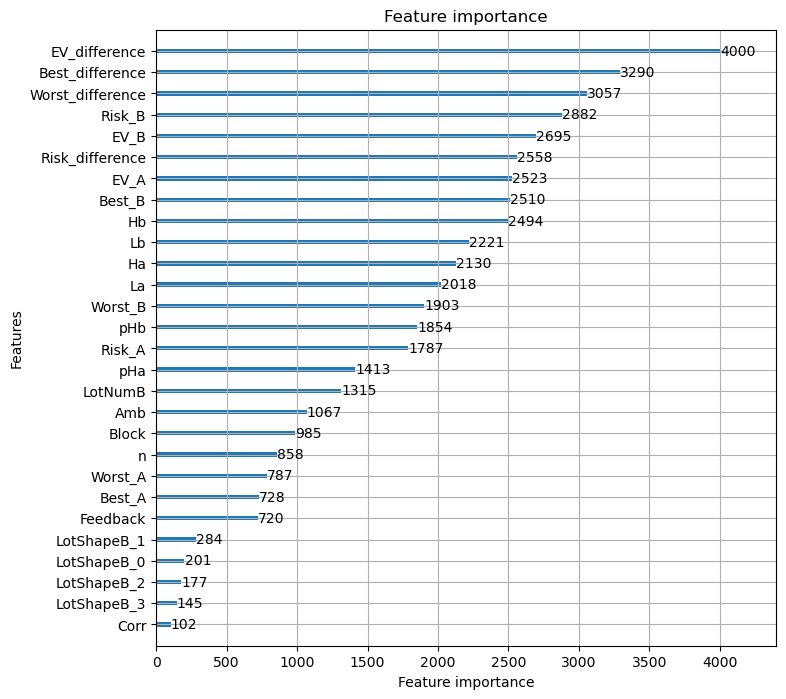

In [148]:
_ = lgb.plot_importance(final_model_optuna, figsize=(8, 8))

*Results*
- The most frequently used feature is the expected value difference between options (A and B), indicating that it provides consistently informative and useful decision thresholds. Differences in best and worst outcomes are also commonly selected, while risk-related (Risk_B, Risk_difference) and option-specific (EV_B, EV_A, Best_B) features are used less frequently by the model. Features with low importance are rarely used for splitting and therefore contribute less to the model’s decision structure.

4. ##### Neural Network: TensorFlow

- Imports 
- A fixed random seed (SEED = 42) is used to make the results as reproducible as possible. The code sets:
    - *PYTHONHASHSEED*: stabilize Python hashing
    - *TF_DETERMINISTIC_OPS=1*: request deterministic TensorFlow operations
    - *CUDA_VISIBLE_DEVICES=""* to force CPU execution (CPU is typically more deterministic than GPU)
    - This increases reproducibility and reduces randomness; results should be the same or extremely close across runs
- Data loading and define target/features
    - target (y): *bRate* (a continuous value in \([0,1]\), representing the average proportion of people choosing option B)
    - features (X): all remaining columns except identifiers/statistics that should not be used as predictors
    - From the matrix X we remove the target variable and other non-predictive or auxiliary columns
        - target: *bRate*
        - non-predictive identifier: *Problem*
        - auxiliary/post-outcome variable: *bRate_std* (it leaks information about the target)
- Basic preprocessing
    - Boolean columns are converted to numeric (0/1) so they can be used by the model
    - All feature columns are coerced to numeric using *pd.to_numeric(errors="coerce")*
    - Any non-numeric values become *NaN*, which are handled later with imputation
- Hold-out test split (unseen data)
    - Split the data into:
        - *train_all* (80%): used for cross-validation and final training
        - *test* (20%): kept completely unseen until the very end
        - This prevents information leakage and allows a final unbiased evaluation on truly unseen data
- Baseline neural network model
    - A simple Multi-Layer Perceptron (MLP) is used:
        - Dense(128, ReLU)
        - Dropout(0.2) for regularization
        - Dense(64, ReLU)
        - Dense(1, Sigmoid)
    - *Sigmoid* output because *bRate* lies in \([0,1]\)
    - Training setup:
        - *Adam optimizer* (learning rate $10^{-3}$)
        - *MSE loss* (regression objective)
        - *MAE metric* for interpretability (average absolute prediction error)
- Training control: early stopping and pruning
    - Two callbacks reduce overfitting and wasted computation:
        - *EarlyStopping*
            - Monitors validation MAE (*val_mae*)
            - Stops when performance stops improving for a number of epochs
            - Restores the best weights found during training
        - *Custom ValMAEPruner*
            - Waits for a warm-up period (first 15 epochs)
            - Stops training early if validation MAE becomes:
                - worse than an absolute cutoff (e.g., > 0.12), or
                - much worse than the best MAE so far (best × 1.3)
        - This speeds up training during cross-validation by terminating clearly poor runs
- K-Fold cross-validation (on train_all only)
    - Perform *5-fold cross-validation* using only the training portion (*train_all*)
    - For each fold:
        - Split into fold-train and fold-validation
        - *Impute missing values using the fold-train medians only* (prevents leakage of validation information)
        - *Standardize features using fold-train only* *StandardScaler* is fit on fold-train and applied to fold-validation
        - Train the neural network with callbacks (pruner + early stopping)
        - Compute fold metrics:
            - MAE
            - RMSE
            - \(R^2\)
    - Report the mean and standard deviation across folds, giving an estimate of generalization performance and stability
- Final training and held-out test evaluation
    - After cross-validation, we train one final model using all *train_all*
    - Because the final model still needs early stopping, we create a small *internal validation split* from *train_all* (e.g., 15%).
    - Then:
        - Impute and scale using *final-train only*
        - Train the model with early stopping/pruning
        - Evaluate once on the *held-out test set*, which has never been used in:
        - cross-validation
        - scaling/imputation fitting
        - model selection decisions
    -  The final reported metrics (MAE, RMSE, \(R^2\)) reflect performance on truly unseen data

In [149]:
import numpy as np
import pandas as pd
import os

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["CUDA_VISIBLE_DEVICES"] = ""   # CPU only = most deterministic

import tensorflow as tf
import random

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# load + basic preprocessing
df = pd.read_csv("c13k_selections.csv")

y = df["bRate"].astype(np.float32)
drop_cols = ["bRate", "Problem", "bRate_std"]
X = df.drop(columns=drop_cols, errors="ignore").copy()

# bool -> 0/1
for col in X.columns:
    if X[col].dtype == "bool":
        X[col] = X[col].astype(np.int8)

# numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Hold-out test split (never used in CV)
X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

# model + callbacks
def build_baseline(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")  # bRate in [0,1]
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="mse",
        metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae")]
    )
    return model

class ValMAEPruner(tf.keras.callbacks.Callback):
    def __init__(self, warmup_epochs=15, absolute_mae_cutoff=None, worse_than_best_factor=1.3):
        super().__init__()
        self.warmup_epochs = warmup_epochs
        self.absolute_mae_cutoff = absolute_mae_cutoff
        self.worse_than_best_factor = worse_than_best_factor
        self.best = np.inf

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_mae = logs.get("val_mae")
        if val_mae is None:
            return

        if val_mae < self.best:
            self.best = val_mae

        if epoch + 1 < self.warmup_epochs:
            return

        if self.absolute_mae_cutoff is not None and val_mae > self.absolute_mae_cutoff:
            print(f"\n[PRUNE] val_mae={val_mae:.6f} > cutoff={self.absolute_mae_cutoff:.6f}")
            self.model.stop_training = True

        if val_mae > self.best * self.worse_than_best_factor:
            print(f"\n[PRUNE] val_mae={val_mae:.6f} > best*{self.worse_than_best_factor}")
            self.model.stop_training = True

def make_callbacks():
    pruner = ValMAEPruner(
        warmup_epochs=15,
        absolute_mae_cutoff=0.12,
        worse_than_best_factor=1.3
    )
    es = tf.keras.callbacks.EarlyStopping(
        monitor="val_mae", mode="min",
        patience=20, restore_best_weights=True, verbose=0
    )
    return [pruner, es]

# K-Fold CV on train_all
K = 5
kf = KFold(n_splits=K, shuffle=True, random_state=SEED)

X_train_all_np = X_train_all.reset_index(drop=True)
y_train_all_np = pd.Series(y_train_all).reset_index(drop=True)

fold_metrics = []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_all_np), start=1):
    X_tr = X_train_all_np.iloc[tr_idx].copy()
    X_val = X_train_all_np.iloc[val_idx].copy()
    y_tr = y_train_all_np.iloc[tr_idx].to_numpy(np.float32)
    y_val = y_train_all_np.iloc[val_idx].to_numpy(np.float32)

    # impute using fold-train medians only
    med = X_tr.median(numeric_only=True)
    X_tr = X_tr.fillna(med)
    X_val = X_val.fillna(med)

    # scale using fold-train only
    num_cols = X_tr.select_dtypes(include=[np.number]).columns
    scaler = StandardScaler()
    X_tr[num_cols] = scaler.fit_transform(X_tr[num_cols])
    X_val[num_cols] = scaler.transform(X_val[num_cols])

    # float32 arrays
    X_tr_arr = X_tr.astype(np.float32).to_numpy()
    X_val_arr = X_val.astype(np.float32).to_numpy()

    # build + train
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = build_baseline(X_tr_arr.shape[1])
    history = model.fit(
        X_tr_arr, y_tr,
        validation_data=(X_val_arr, y_val),
        epochs=300,
        batch_size=128,
        verbose=0,
        callbacks=make_callbacks()
    )

    # fold predictions + metrics
    val_pred = model.predict(X_val_arr, verbose=0).ravel()
    mae = mean_absolute_error(y_val, val_pred)
    rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    r2 = r2_score(y_val, val_pred)

    best_val_mae = float(np.min(history.history["val_mae"]))
    fold_metrics.append((mae, rmse, r2, best_val_mae))

    print(f"Fold {fold}/{K} | MAE={mae:.6f} | RMSE={rmse:.6f} | R2={r2:.6f} | best_val_mae(history)={best_val_mae:.6f}")

fold_metrics = np.array(fold_metrics)  # cols: [mae, rmse, r2, best_val_mae]

print("\nCV SUMMARY (on train_all only)")
print(f"MAE : {fold_metrics[:,0].mean():.6f}")
print(f"RMSE: {fold_metrics[:,1].mean():.6f}")
print(f"R²  : {fold_metrics[:,2].mean():.6f}")

# final train on all train_all, test once on held-out test
# Build a small internal val split for early stopping while training final model
X_trF, X_valF, y_trF, y_valF = train_test_split(
    X_train_all.copy(), y_train_all.astype(np.float32),
    test_size=0.15, random_state=SEED
)

# Impute/scale using final-train only
medF = X_trF.median(numeric_only=True)
X_trF = X_trF.fillna(medF)
X_valF = X_valF.fillna(medF)
X_testF = X_test.copy().fillna(medF)

num_colsF = X_trF.select_dtypes(include=[np.number]).columns
scalerF = StandardScaler()
X_trF[num_colsF] = scalerF.fit_transform(X_trF[num_colsF])
X_valF[num_colsF] = scalerF.transform(X_valF[num_colsF])
X_testF[num_colsF] = scalerF.transform(X_testF[num_colsF])

X_trF = X_trF.astype(np.float32).to_numpy()
X_valF = X_valF.astype(np.float32).to_numpy()
X_testF = X_testF.astype(np.float32).to_numpy()
y_testF = y_test.astype(np.float32)

tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

final_model = build_baseline(X_trF.shape[1])
final_model.fit(
    X_trF, y_trF,
    validation_data=(X_valF, y_valF.astype(np.float32)),
    epochs=300,
    batch_size=128,
    verbose=0,
    callbacks=make_callbacks()
)

test_pred = final_model.predict(X_testF, verbose=0).ravel()
test_mae = mean_absolute_error(y_testF, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_testF, test_pred))
test_r2 = r2_score(y_testF, test_pred)

print("\nHELD-OUT TEST (real unseen data)")
print(f"TEST MAE : {test_mae:.6f}")
print(f"TEST RMSE: {test_rmse:.6f}")
print(f"TEST R^2 : {test_r2:.6f}")


Fold 1/5 | MAE=0.084130 | RMSE=0.107439 | R2=0.756981 | best_val_mae(history)=0.084130
Fold 2/5 | MAE=0.082549 | RMSE=0.104793 | R2=0.783770 | best_val_mae(history)=0.082549
Fold 3/5 | MAE=0.083570 | RMSE=0.105741 | R2=0.768211 | best_val_mae(history)=0.083570
Fold 4/5 | MAE=0.082370 | RMSE=0.103928 | R2=0.779923 | best_val_mae(history)=0.082370
Fold 5/5 | MAE=0.083014 | RMSE=0.106962 | R2=0.773973 | best_val_mae(history)=0.083014

CV SUMMARY (on train_all only)
MAE : 0.083127
RMSE: 0.105773
R²  : 0.772571

HELD-OUT TEST (real unseen data)
TEST MAE : 0.080479
TEST RMSE: 0.102760
TEST R^2 : 0.784308


*Result Explanation*
- A neural network model was used to capture complex nonlinear relationships in the data. Cross-validation results showed stable and consistent performance across folds, with a mean MAE of 0.0831, a mean RMSE of 0.1057, and a mean R² of 0.772, indicating reliable generalization within the training data. On the held-out test set, the model achieved an MAE of 0.0804, meaning that, on average, the predicted choice probabilities deviated from the true values by approximately 8.0 percentage points. The corresponding test RMSE was 0.1027, which was only moderately larger than the MAE, suggesting that large prediction errors were relatively infrequent. In addition, the model achieved a test R² of 0.784, indicating that it explains approximately 78% of the variance in choice rates. Overall, the neural network substantially outperformed the linear baseline and achieved performance comparable to tree-based models.

### Best MAE = 0.07384468050804173